In [1]:
import os
# find where train.csv actually is
for root, dirs, files in os.walk('/kaggle/input'):
    if 'train.csv' in files:
        print(f"FOUND: {root}")
        print(os.listdir(root)[:20])
        break

print("\n--- All input folders ---")
print(os.listdir('/kaggle/input'))

FOUND: /kaggle/input/competitions/birdclef-2025
['sample_submission.csv', 'taxonomy.csv', 'train_audio', 'train_soundscapes', 'train.csv', 'recording_location.txt', 'test_soundscapes']

--- All input folders ---
['competitions']


In [2]:
import  pandas as pd

BASE = "/kaggle/input/competitions/birdclef-2025"  # <-- CHANGE THIS to what FOUND printed
# example: BASE = "/kaggle/input/birdclef-2025/birdclef-2025" if needed

train = pd.read_csv(f"{BASE}/train.csv")
taxonomy = pd.read_csv(f"{BASE}/taxonomy.csv")
print(BASE, train.shape)

/kaggle/input/competitions/birdclef-2025 (28564, 13)


# BirdCLEF Audio Visualization

This code loads one BirdCLEF 2025 training audio file, converts it into a mel-spectrogram, and displays the result.

## 1. Import Libraries

```python
import librosa
import librosa.display
import matplotlib.pyplot as plt
import os
```

- `librosa`: Loads and analyzes audio files.
- `librosa.display`: Provides functions for displaying audio features such as spectrograms.
- `matplotlib.pyplot`: Creates plots and visualizations.
- `os`: Handles file and directory paths.

The code also requires pandas:

```python
import pandas as pd
```

## 2. Define the Dataset Path

```python
BASE = "/kaggle/input/competitions/birdclef-2025"
```

`BASE` stores the location of the BirdCLEF 2025 dataset in the Kaggle environment.

## 3. Load the Training Metadata

```python
train = pd.read_csv(f"{BASE}/train.csv")
```

This reads `train.csv` into a pandas DataFrame called `train`.

The CSV file contains information about the audio files, including:

- `filename`: The audio file path or name
- `primary_label`: The bird species label

## 4. Select One Audio Record

```python
row = train.iloc[0]
```

`iloc[0]` selects the first row from the DataFrame.

```python
path = os.path.join(BASE, "train_audio", row['filename'])
```

This creates the complete path to the selected audio file by joining:

- The dataset directory
- The `train_audio` directory
- The filename from the CSV file

## 5. Load the Audio

```python
y, sr = librosa.load(path, sr=32000)
```

This loads the audio file using Librosa.

- `y`: The audio waveform represented as numerical samples
- `sr`: The sampling rate, set to `32000` samples per second
- `sr=32000`: Resamples the audio to 32 kHz if necessary

## 6. Create a Mel-Spectrogram

```python
mels = librosa.feature.melspectrogram(
    y=y,
    sr=sr,
    n_mels=128,
    fmin=50,
    fmax=14000
)
```

A mel-spectrogram represents the frequency content of an audio signal over time.

Parameters:

- `y=y`: The loaded audio waveform
- `sr=sr`: The audio sampling rate
- `n_mels=128`: Uses 128 mel-frequency bands
- `fmin=50`: Minimum frequency is 50 Hz
- `fmax=14000`: Maximum frequency is 14,000 Hz

The result is a two-dimensional array where:

- The horizontal axis represents time
- The vertical axis represents frequency
- The values represent sound energy

## 7. Convert to Decibel Scale

```python
log_mels = librosa.power_to_db(mels)
```

This converts the power values of the mel-spectrogram into decibels.

The decibel scale makes the visualization easier to interpret because it represents sound intensity using a logarithmic scale.

## 8. Create the Plot

```python
plt.figure(figsize=(10, 4))
```

Creates a plot that is 10 inches wide and 4 inches high.

```python
librosa.display.specshow(
    log_mels,
    sr=sr,
    x_axis='time'
)
```

Displays the mel-spectrogram.

- `log_mels`: The spectrogram in decibel scale
- `sr=sr`: Provides the sampling rate
- `x_axis='time'`: Labels the horizontal axis using time values

```python
plt.title(f"{row['primary_label']} - {row['filename']}")
```

Sets the plot title using the bird species label and audio filename.

```python
plt.show()
```

Displays the plot.

## 9. Print the Audio Duration

```python
print("Duration:", len(y) / sr, "sec")
```

Calculates the duration of the audio file.

- `len(y)`: Number of audio samples
- `sr`: Number of samples per second
- `len(y) / sr`: Audio duration in seconds

## Overall Workflow

The code performs the following steps:

1. Loads the dataset metadata.
2. Selects the first audio file.
3. Loads and resamples the audio to 32 kHz.
4. Converts the audio into a mel-spectrogram.
5. Converts the spectrogram to decibel values.
6. Displays the spectrogram.
7. Prints the audio duration.

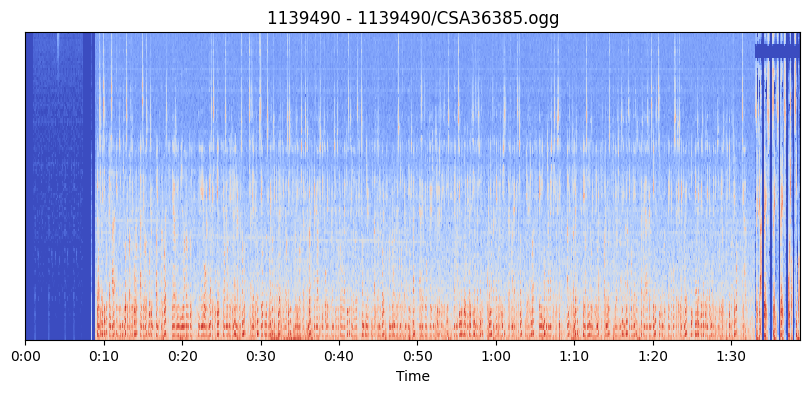

Duration: 98.853375 sec


In [3]:
import librosa, librosa.display
import matplotlib.pyplot as plt
import os

BASE = "/kaggle/input/competitions/birdclef-2025"
train = pd.read_csv(f"{BASE}/train.csv")

row = train.iloc[0]
path = os.path.join(BASE, "train_audio", row['filename'])

y, sr = librosa.load(path, sr=32000)
mels = librosa.feature.melspectrogram(y=y, sr=sr, n_mels=128, fmin=50, fmax=14000)
log_mels = librosa.power_to_db(mels)

plt.figure(figsize=(10,4))
librosa.display.specshow(log_mels, sr=sr, x_axis='time')
plt.title(f"{row['primary_label']} - {row['filename']}")
plt.show()

print("Duration:", len(y)/sr, "sec")

In [4]:
train.head()

,primary_label,secondary_labels,type,filename,collection,rating,url,latitude,longitude,scientific_name,common_name,author,license
0,1139490,[''],[''],1139490/CSA36385.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
1,1139490,[''],[''],1139490/CSA36389.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3206,-73.7128,Ragoniella pulchella,Ragoniella pulchella,Fabio A. Sarria-S,cc-by-nc-sa 4.0
2,1192948,[''],[''],1192948/CSA36358.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
3,1192948,[''],[''],1192948/CSA36366.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.2800,-73.8582,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0
4,1192948,[''],[''],1192948/CSA36373.ogg,CSA,0.0,http://colecciones.humboldt.org.co/rec/sonidos...,7.3791,-73.7313,Oxyprora surinamensis,Oxyprora surinamensis,Fabio A. Sarria-S,cc-by-nc-sa 4.0


# BirdCLEF PyTorch Dataset

This code prepares BirdCLEF audio files for training a PyTorch bird-species classification model.

It performs the following tasks:

1. Creates mappings between bird labels and numbers.
2. Defines audio-processing settings.
3. Creates a custom PyTorch `Dataset`.
4. Loads and preprocesses audio files.
5. Converts audio into mel-spectrograms.
6. Creates a `DataLoader` for batching samples.

## 1. Import Libraries

```python
import torch
import torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
```

- `torch`: Main PyTorch library for tensors and deep learning.
- `torchaudio`: Provides audio loading and audio transformations.
- `torch.nn.functional`: Contains functions such as padding.
- `Dataset`: Base class for creating custom datasets.
- `DataLoader`: Loads dataset samples in batches.

The code also assumes that these variables were defined earlier:

```python
import os
BASE = "path/to/birdclef-2025"
train = pd.read_csv("train.csv")
```

## 2. Create Label Mappings

```python
labels = sorted(train['primary_label'].unique())
```

Gets all unique bird species labels from the `primary_label` column and sorts them alphabetically.

```python
label2idx = {l: i for i, l in enumerate(labels)}
```

Creates a mapping from each bird label to an integer index.

Example:

```python
{
    "bird_a": 0,
    "bird_b": 1,
    "bird_c": 2
}
```

Neural networks work with numerical labels instead of text labels.

```python
idx2label = {i: l for l, i in label2idx.items()}
```

Creates the reverse mapping from an integer index back to the original bird label.

```python
print(f"Num classes: {len(labels)}")
```

Prints the total number of bird species classes.

## 3. Define Configuration Settings

```python
class CFG:
    SR = 32000
    DURATION = 5
    N_MELS = 128
    BATCH = 32
```

The `CFG` class stores configuration values in one place.

- `SR = 32000`: Audio sampling rate of 32,000 samples per second.
- `DURATION = 5`: Each audio example will be five seconds long.
- `N_MELS = 128`: Each mel-spectrogram will contain 128 frequency bands.
- `BATCH = 32`: Intended default batch size.

In the example below, a batch size of `8` is used instead of `CFG.BATCH`.

## 4. Define the Custom Dataset

```python
class BirdDataset(Dataset):
```

`BirdDataset` is a custom PyTorch dataset. It tells PyTorch how to:

- Count the samples.
- Load an individual audio file.
- Process the audio.
- Return the input spectrogram and its label.

## 5. Dataset Initialization

```python
def __init__(self, df):
    self.df = df
```

Stores the input pandas DataFrame.

The DataFrame should contain at least:

- `filename`
- `primary_label`

### Mel-Spectrogram Transform

```python
self.mel = torchaudio.transforms.MelSpectrogram(
    sample_rate=CFG.SR,
    n_mels=CFG.N_MELS,
    f_min=50,
    f_max=14000,
    n_fft=1024,
    hop_length=512
)
```

Creates a transform that converts a waveform into a mel-spectrogram.

Parameters:

- `sample_rate=CFG.SR`: Uses a 32 kHz sampling rate.
- `n_mels=128`: Creates 128 mel-frequency bands.
- `f_min=50`: Ignores frequencies below 50 Hz.
- `f_max=14000`: Ignores frequencies above 14,000 Hz.
- `n_fft=1024`: Uses 1,024 samples for each short-time Fourier transform window.
- `hop_length=512`: Moves the analysis window 512 samples at a time.

### Convert Amplitude to Decibels

```python
self.db = torchaudio.transforms.AmplitudeToDB()
```

Converts the mel-spectrogram values into decibel units. This usually creates a more useful scale for audio visualization and model training.

## 6. Return the Dataset Length

```python
def __len__(self):
    return len(self.df)
```

Returns the number of audio records in the dataset.

PyTorch uses this method to determine how many samples are available.

## 7. Load One Audio Sample

```python
def __getitem__(self, idx):
```

Loads and processes one sample using its index.

```python
row = self.df.iloc[idx]
```

Selects one row from the DataFrame.

```python
path = os.path.join(BASE, "train_audio", row['filename'])
```

Builds the full path to the audio file.

## 8. Load and Convert the Audio to Mono

```python
wav, sr = torchaudio.load(path)
```

Loads the audio file.

- `wav`: Audio waveform tensor.
- `sr`: Original sampling rate of the file.

```python
wav = wav.mean(dim=0)
```

Converts stereo or multi-channel audio into mono by averaging all channels.

After this operation, `wav` contains one audio channel.

> Note: If files have different sampling rates, they should be resampled to `CFG.SR` before creating the mel-spectrogram.

## 9. Crop or Pad the Audio

```python
target = CFG.SR * CFG.DURATION
```

Calculates the required number of samples for a five-second clip.

With a 32 kHz sampling rate:

```text
32,000 samples/second × 5 seconds = 160,000 samples
```

### Crop Long Audio

```python
if len(wav) > target:
    start = torch.randint(0, len(wav) - target, (1,)).item()
    wav = wav[start:start + target]
```

If the audio is longer than five seconds:

1. Selects a random starting position.
2. Extracts a five-second section.

Random cropping provides data variation during training.

### Pad Short Audio

```python
else:
    wav = F.pad(wav, (0, target - len(wav)))
```

If the audio is shorter than five seconds, zeros are added to the end until it reaches the required length.

This ensures that every audio sample has the same duration.

## 10. Convert Audio to a Mel-Spectrogram

```python
mel = self.mel(wav)
```

Converts the waveform into a mel-spectrogram.

The output has approximately this shape:

```text
[128, 313]
```

- `128`: Number of mel-frequency bands.
- `313`: Number of time frames created from the five-second waveform.

The exact number of frames can depend on transform settings such as padding and window behavior.

```python
mel = self.db(mel)
```

Converts the mel-spectrogram from amplitude or power values into decibels.

## 11. Normalize the Spectrogram

```python
mel = (mel - mel.mean()) / (mel.std() + 1e-6)
```

Standardizes the mel-spectrogram.

- Subtracting `mel.mean()` centers the values around zero.
- Dividing by `mel.std()` scales the values.
- `1e-6` prevents division by zero.

Normalization helps the neural network train more efficiently.

## 12. Convert the Label to an Integer

```python
label = label2idx[row['primary_label']]
```

Converts the text bird label into its corresponding integer class index.

For example:

```text
"bird_a" → 0
```

```python
return mel, label
```

Returns two values:

- `mel`: The processed mel-spectrogram.
- `label`: The numerical bird-species class.

## 13. Select a Smaller Dataset

```python
small_df = train.sample(200, random_state=42)
```

Randomly selects 200 records from the training DataFrame.

The `random_state=42` value makes the selection reproducible.

This smaller dataset is useful for quickly testing the data pipeline.

## 14. Create the Dataset and DataLoader

```python
ds = BirdDataset(small_df)
```

Creates an instance of the custom dataset.

```python
loader = DataLoader(
    ds,
    batch_size=8,
    shuffle=True
)
```

Creates a `DataLoader`.

- `ds`: Dataset to load.
- `batch_size=8`: Loads eight samples at a time.
- `shuffle=True`: Randomizes the sample order.

## 15. Read One Batch

```python
mels, labs = next(iter(loader))
```

Creates an iterator over the DataLoader and retrieves the first batch.

- `mels`: Batch of mel-spectrograms.
- `labs`: Batch of numerical labels.

```python
print("Batch mel shape:", mels.shape)
```

For this configuration, the shape should be approximately:

```text
[8, 128, 313]
```

The dimensions represent:

1. `8`: Number of audio samples in the batch.
2. `128`: Number of mel-frequency bands.
3. `313`: Number of time frames.

```python
print("Batch labels:", labs)
```

Prints the integer labels for the eight audio samples.

## Overall Workflow

The complete pipeline is:

```text
Audio file
    ↓
Load waveform
    ↓
Convert to mono
    ↓
Crop or pad to 5 seconds
    ↓
Create mel-spectrogram
    ↓
Convert values to decibels
    ↓
Normalize features
    ↓
Convert species label to an integer
    ↓
Return sample and label
    ↓
Group samples into batches
```

This processed data can then be passed to a PyTorch neural network for bird-species classification.

In [5]:
train['primary_label'].unique()

array(['1139490', '1192948', '1194042', '126247', '1346504', '134933',
       '135045', '1462711', '1462737', '1564122', '21038', '21116',
       '21211', '22333', '22973', '22976', '24272', '24292', '24322',
       '41663', '41778', '41970', '42007', '42087', '42113', '46010',
       '47067', '476537', '476538', '48124', '50186', '517119', '523060',
       '528041', '52884', '548639', '555086', '555142', '566513', '64862',
       '65336', '65344', '65349', '65373', '65419', '65448', '65547',
       '65962', '66016', '66531', '66578', '66893', '67082', '67252',
       '714022', '715170', '787625', '81930', '868458', '963335',
       'amakin1', 'amekes', 'ampkin1', 'anhing', 'babwar', 'bafibi1',
       'banana', 'baymac', 'bbwduc', 'bicwre1', 'bkcdon', 'bkmtou1',
       'blbgra1', 'blbwre1', 'blcant4', 'blchaw1', 'blcjay1', 'blctit1',
       'blhpar1', 'blkvul', 'bobfly1', 'bobher1', 'brtpar1', 'bubcur1',
       'bubwre1', 'bucmot3', 'bugtan', 'butsal1', 'cargra1', 'cattyr',
       'chb

In [6]:
train.iloc[0]

primary_label                                                 1139490
secondary_labels                                                 ['']
type                                                             ['']
filename                                         1139490/CSA36385.ogg
collection                                                        CSA
rating                                                            0.0
url                 http://colecciones.humboldt.org.co/rec/sonidos...
latitude                                                       7.3206
longitude                                                    -73.7128
scientific_name                                  Ragoniella pulchella
common_name                                      Ragoniella pulchella
author                                              Fabio A. Sarria-S
license                                               cc-by-nc-sa 4.0
Name: 0, dtype: object

In [7]:
import torch, torchaudio
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

# Label map
labels = sorted(train['primary_label'].unique())
label2idx = {l:i for i,l in enumerate(labels)}
idx2label = {i:l for l,i in label2idx.items()}
print(f"Num classes: {len(labels)}")

class CFG:
    SR = 32000       # Sample rate (32kHz)
    DURATION = 5     # Every clip is fixed at 5 seconds
    N_MELS = 128     # 128 Mel frequency bins
    BATCH = 32       # Batch size

class BirdDataset(Dataset):
    def __init__(self, df):
        self.df = df
        self.mel = torchaudio.transforms.MelSpectrogram(
            sample_rate=CFG.SR, n_mels=CFG.N_MELS, f_min=50, f_max=14000, n_fft=1024, hop_length=512
        )
        self.db = torchaudio.transforms.AmplitudeToDB()
        
    def __len__(self): return len(self.df)
    
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = os.path.join(BASE, "train_audio", row['filename'])
        
        wav, sr = torchaudio.load(path)
        wav = wav.mean(dim=0) # mono
        
        # crop/pad to 5 sec
        if sr != CFG.SR:
            resampler = torchaudio.transforms.Resample(orig_freq=sr, new_freq=CFG.SR)
            wav = resampler(wav)
            
        target = CFG.SR * CFG.DURATION
        if len(wav) > target:
            start = torch.randint(0, len(wav)-target, (1,)).item()
            wav = wav[start:start+target]
        else:
            wav = F.pad(wav, (0, target - len(wav)))
            
        mel = self.mel(wav)
        mel = self.db(mel)
        mel = (mel - mel.mean()) / (mel.std() + 1e-6)
        
        label = label2idx[row['primary_label']]
        return mel, label

# Test on 200 samples only (fast)
small_df = train.sample(200, random_state=42)
ds = BirdDataset(small_df)
loader = DataLoader(ds, batch_size=8, shuffle=True)

mels, labs = next(iter(loader))
print("Batch mel shape:", mels.shape) # should be [8, 128, 313]
print("Batch labels:", labs)

Num classes: 206
Batch mel shape: torch.Size([8, 128, 313])
Batch labels: tensor([ 66, 119, 166, 113, 119, 183, 166, 123])


In [8]:
for lab in labs:
    print(int(lab), "→", idx2label[int(lab)])

66 → banana
119 → gycwor1
166 → soulap1
113 → grekis
119 → gycwor1
183 → verfly
166 → soulap1
123 → linwoo1


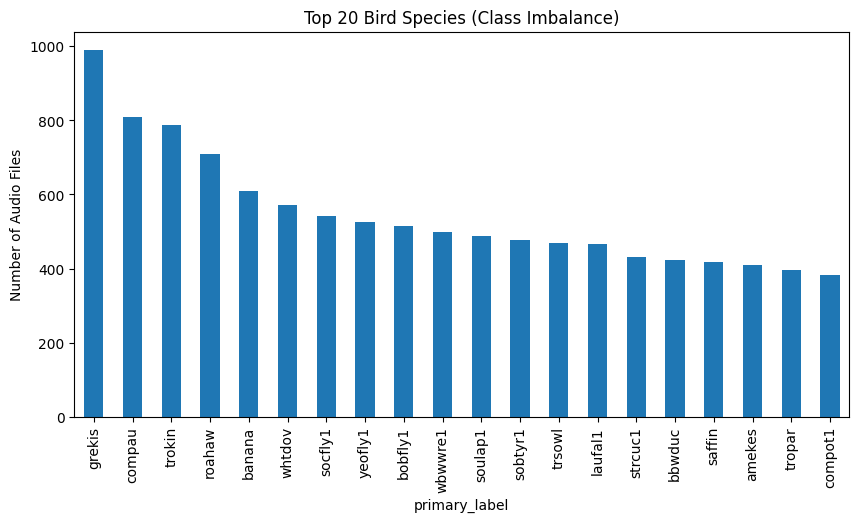

In [9]:
plt.figure(figsize=(10,5))
train['primary_label'].value_counts().head(20).plot(kind='bar')
plt.title("Top 20 Bird Species (Class Imbalance)")
plt.ylabel("Number of Audio Files")
plt.savefig("class_imbalance.png")  # Save it!
plt.show()

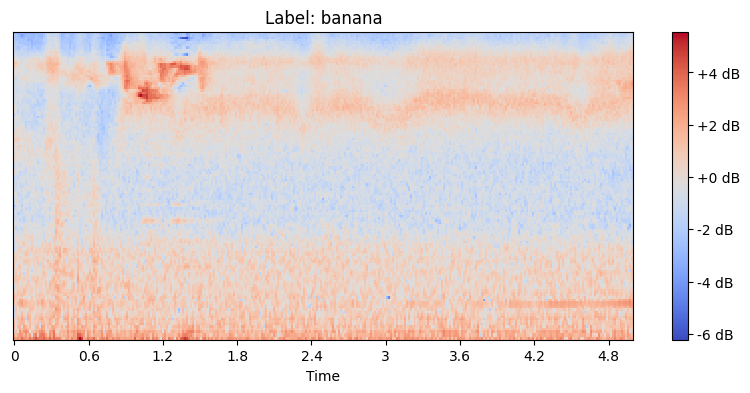

In [10]:
plt.figure(figsize=(10,4))
# Use mel[0] (first sample in batch), squeeze to remove channel dim if needed
librosa.display.specshow(mels[0].numpy(), sr=CFG.SR, x_axis='time')
plt.title(f"Label: {idx2label[int(labs[0])]}")
plt.colorbar(format='%+2.0f dB')
plt.savefig("batch_spectrogram.png")
plt.show()